# Part 1 ‐ Exploratory data analysis

The attached logins.json file contains (simulated) timestamps of user logins in a particular
geographic location. Aggregate these login counts based on 15minute time intervals, and
visualize and describe the resulting time series of login counts in ways that best characterize the
underlying patterns of the demand. Please report/illustrate important features of the demand,
such as daily cycles. If there are data quality issues, please report them.


In [199]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels as sm
import calendar
from scipy.signal import find_peaks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing  import StandardScaler
from sklearn.linear_model   import LogisticRegression
from sklearn.ensemble    import RandomForestClassifier
from sklearn.metrics        import confusion_matrix,classification_report,roc_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [87]:
df = pd.DataFrame(pd.read_json('Data/logins.json'))
df.head()

,login_time
0,1970-01-01 20:13:18
1,1970-01-01 20:16:10
2,1970-01-01 20:16:37
3,1970-01-01 20:16:36
4,1970-01-01 20:26:21


In [88]:
df.login_time = pd.to_datetime(df.login_time)
df.set_index('login_time', inplace=True)
logins_15min = pd.DataFrame(df.resample('15T').size(), columns=['login_counts'])
logins_15min

C:\Users\rusla\AppData\Local\Temp\ipykernel_17944\319877906.py:3: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  logins_15min = pd.DataFrame(df.resample('15T').size(), columns=['login_counts'])


,login_counts
login_time,
1970-01-01 20:00:00,2
1970-01-01 20:15:00,6
1970-01-01 20:30:00,9
1970-01-01 20:45:00,7
1970-01-01 21:00:00,1
...,...
1970-04-13 17:45:00,5
1970-04-13 18:00:00,5
1970-04-13 18:15:00,2


In [89]:
logins_15min.index.to_series().diff().value_counts()


login_time
0 days 00:15:00    9787
Name: count, dtype: int64

In [90]:
print(logins_15min.index.min(),'\n')
print(logins_15min.index.max())

1970-01-01 20:00:00 

1970-04-13 18:45:00


In [91]:
logins_15min['month'] = logins_15min.index.month
logins_15min['day'] = logins_15min.index.day
logins_15min['hour'] = logins_15min.index.hour
logins_15min['minute'] = logins_15min.index.minute
logins_15min['weekday'] = logins_15min.index.dayofweek
logins_15min

,login_counts,month,day,hour,minute,weekday
login_time,,,,,,
1970-01-01 20:00:00,2,1,1,20,0,3
1970-01-01 20:15:00,6,1,1,20,15,3
1970-01-01 20:30:00,9,1,1,20,30,3
1970-01-01 20:45:00,7,1,1,20,45,3
1970-01-01 21:00:00,1,1,1,21,0,3
...,...,...,...,...,...,...
1970-04-13 17:45:00,5,4,13,17,45,0
1970-04-13 18:00:00,5,4,13,18,0,0
1970-04-13 18:15:00,2,4,13,18,15,0


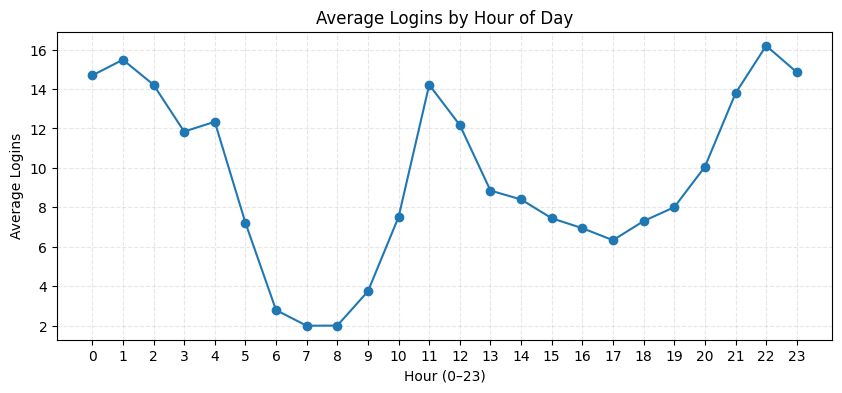

In [116]:
avg_by_hour = logins_15min.groupby('hour')['login_counts'].mean()

plt.figure(figsize=(10, 4))
plt.plot(avg_by_hour.index, avg_by_hour.values, marker='o')
plt.title('Average Logins by Hour of Day')
plt.xlabel('Hour (0–23)')
plt.ylabel('Average Logins')
plt.grid(True, linestyle='--', alpha=0.3)
plt.xticks(range(0, 24));

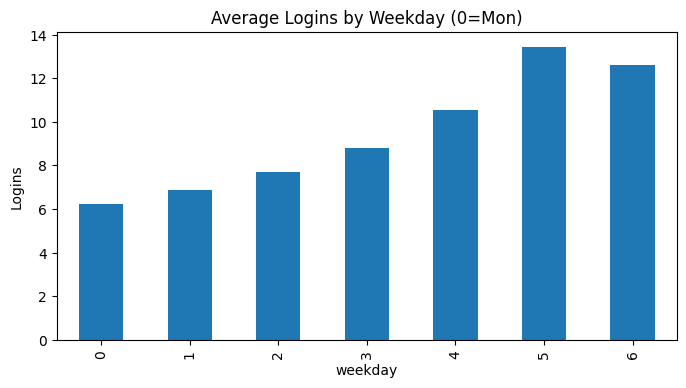

In [93]:
logins_15min.groupby('weekday')['login_counts'].mean().plot(kind='bar', figsize=(8,4), title='Average Logins by Weekday (0=Mon)', ylabel='Logins');

C:\Users\rusla\AppData\Local\Temp\ipykernel_17944\3628340076.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([calendar.day_name[d] for d in range(7)]);


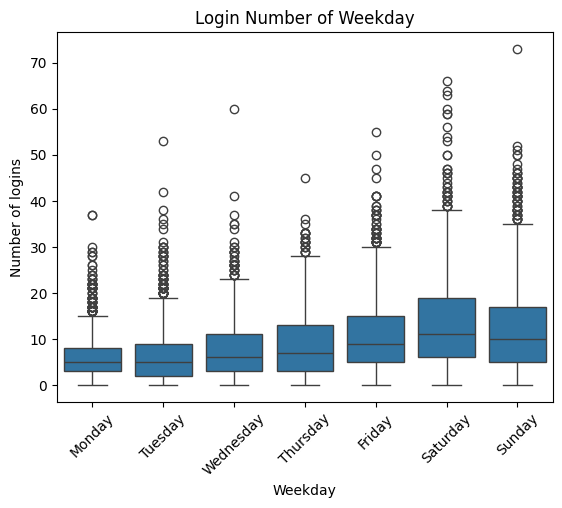

In [120]:
ax = sns.boxplot(x='weekday', y='login_counts', data=logins_15min)
plt.title("Login Number of Weekday")
plt.xlabel("Weekday")
plt.ylabel("Number of logins")
plt.xticks(rotation=45)
ax.set_xticklabels([calendar.day_name[d] for d in range(7)]);

Logins tend to peak late at night and again around midday, with the lowest activity occurring between 6 AM and 9 AM. Weekly trends show a clear rise in login activity from Monday through Saturday, with Saturday being the most active day out of the week.

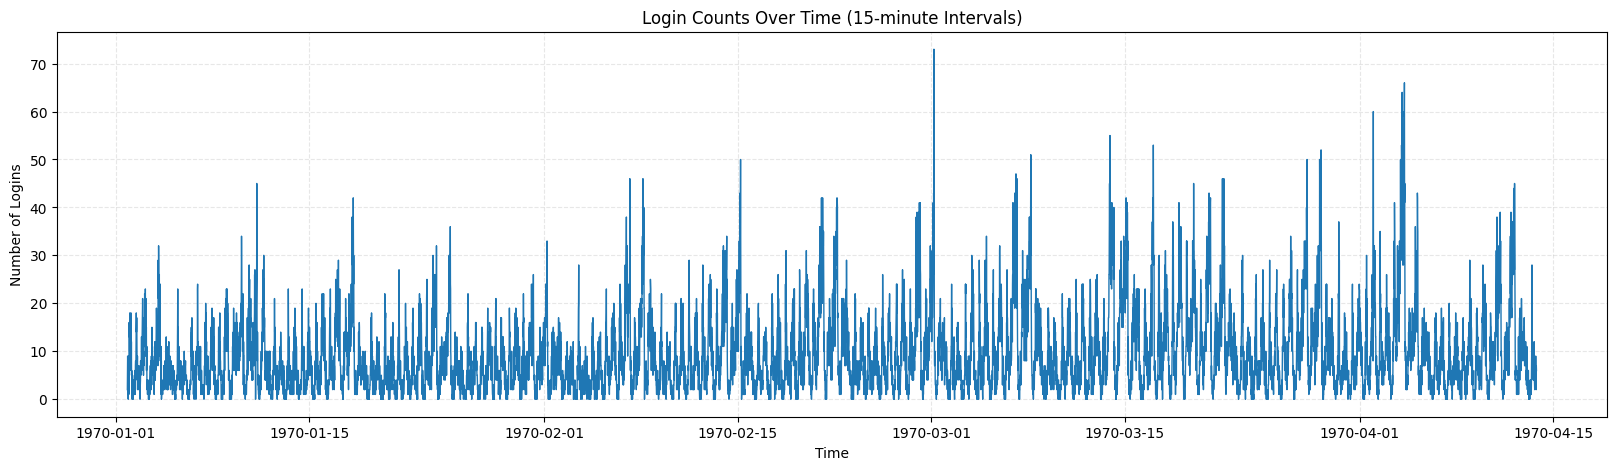

In [94]:
plt.figure(figsize=(20, 5))
plt.plot(logins_15min.index, logins_15min['login_counts'], linewidth=1)
plt.title('Login Counts Over Time (15-minute Intervals)')
plt.xlabel('Time')
plt.ylabel('Number of Logins')
plt.grid(True, linestyle='--', alpha=0.3);

I want to dive into what days are these peaks are occuring

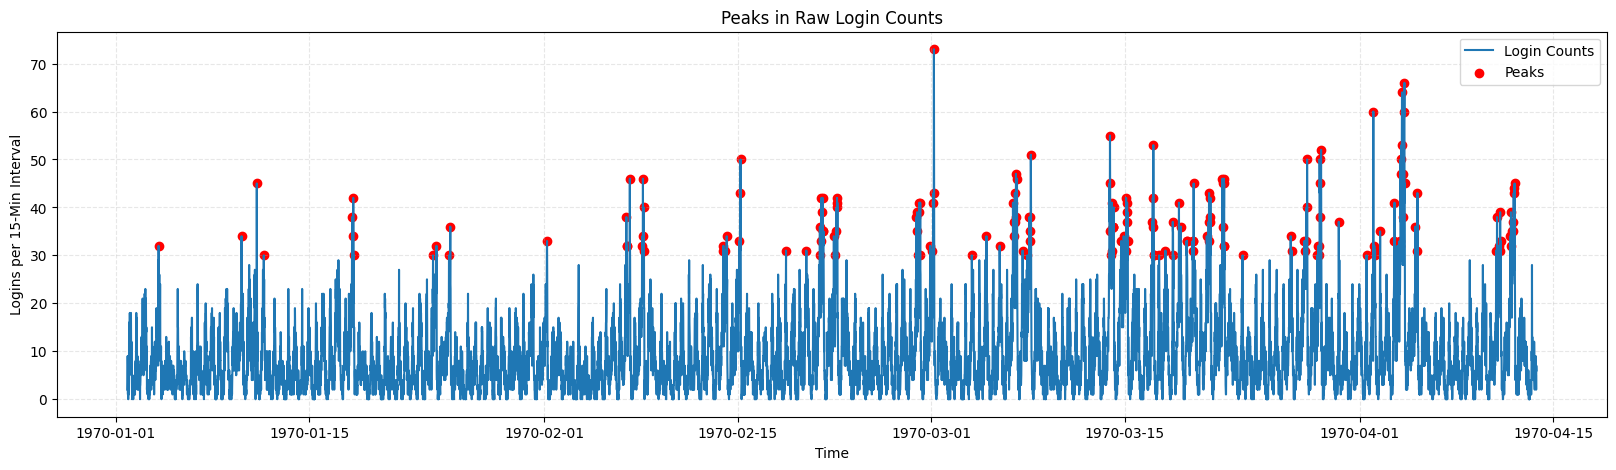

In [102]:
peaks_indices, _ = find_peaks(logins_15min['login_counts'], height=30)
peak_times = logins_15min.iloc[peaks_indices].index
peak_values = logins_15min.iloc[peaks_indices]['login_counts']

plt.figure(figsize=(20, 5))
plt.plot(logins_15min.index, logins_15min['login_counts'], label='Login Counts')
plt.scatter(peak_times, peak_values, color='red', label='Peaks')
plt.title('Peaks in Raw Login Counts')
plt.xlabel('Time')
plt.ylabel('Logins per 15-Min Interval')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)

In [103]:
peak_data = logins_15min.iloc[peaks_indices][['login_counts']]
peak_data['weekday'] = peak_data.index.dayofweek
weekday_map = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}
peak_data['weekday_name'] = peak_data['weekday'].map(weekday_map)
peak_data

,login_counts,weekday,weekday_name
login_time,,,
1970-01-04 02:15:00,32,6,Sun
1970-01-10 02:15:00,34,5,Sat
1970-01-11 04:45:00,45,6,Sun
1970-01-11 16:45:00,30,6,Sun
1970-01-18 02:15:00,38,6,Sun
...,...,...,...
1970-04-12 01:15:00,37,6,Sun
1970-04-12 02:15:00,35,6,Sun
1970-04-12 03:15:00,43,6,Sun


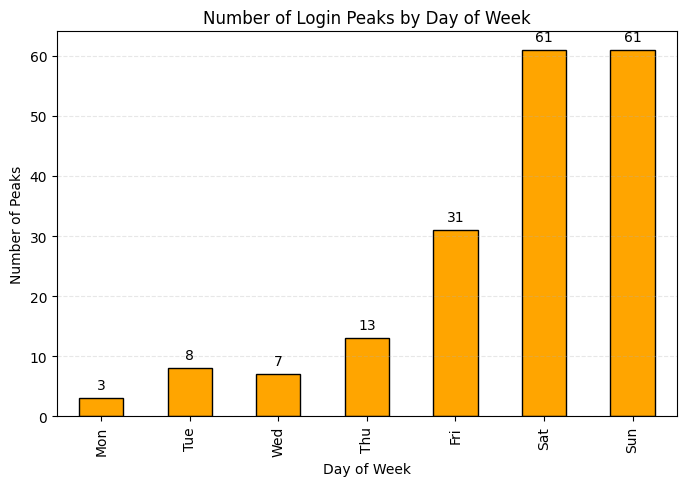

In [110]:
peak_day_counts = peak_data['weekday_name'].value_counts().reindex(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.figure(figsize=(8, 5))
ax = peak_day_counts.plot(kind='bar', color='orange', edgecolor='black')

for i, value in enumerate(peak_day_counts):
    plt.text(i, value + 1, str(value), ha='center', va='bottom', fontsize=10)

plt.title('Number of Login Peaks by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Peaks')
plt.grid(axis='y', linestyle='--', alpha=0.3);

We see that out of the highest peaks most of them occur on the weekend for Saturday and Sunday evenly

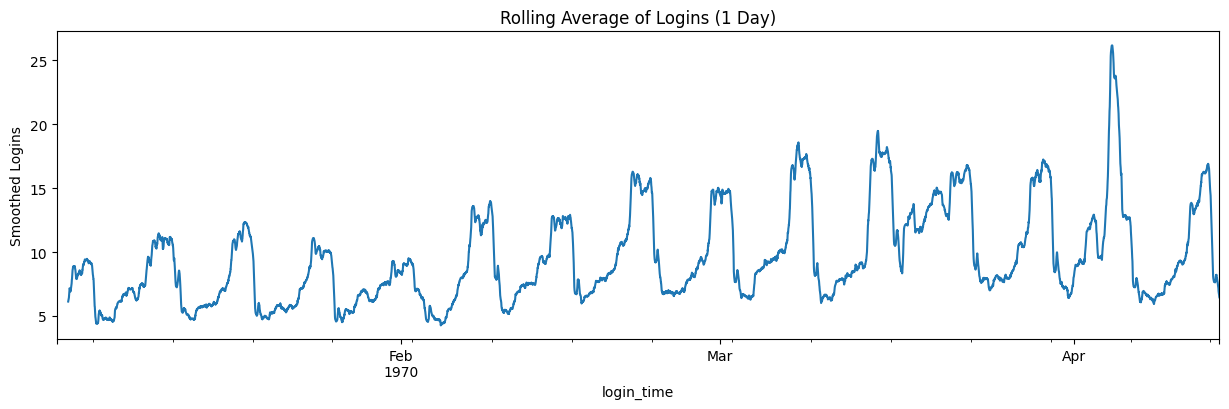

In [114]:
logins_15min['rolling_mean'] = logins_15min['login_counts'].rolling(window=96).mean() 
logins_15min['rolling_mean'].plot(figsize=(15, 4), title='Rolling Average of Logins (1 Day)', ylabel='Smoothed Logins');

The rolling average plot reveals a strong weekly login cycle, with consistent peaks and troughs, and a noticeable spike in early April indicating a short surge in user activity

## Conclusion

The data revealed strong daily cycles, with login activity peaking consistently during the late night and early morning hours. Peaks in login volume were also extracted and visualized, showing that high activity is clustered during late night weekend periods.

No major data quality issues were found; the 15-minute intervals appeared consistent, and outlier values were rare and explainable. Overall, the demand patterns suggest a highly active user base late at night on weekends, providing clear insight into peak usage windows.

# Part 2 - Experiment and Metrics Design

The neighboring cities of Gotham and Metropolis have complementary circadian rhythms: on
weekdays, Ultimate Gotham is most active at night, and Ultimate Metropolis is most active
during the day. On weekends, there is reasonable activity in both cities.
However, a toll bridge, with a two way toll, between the two cities causes driver partners to tend
to be exclusive to each city. The Ultimate managers of city operations for the two cities have
proposed an experiment to encourage driver partners to be available in both cities, by
reimbursing all toll costs.
1) What would you choose as the key measure of success of this experiment in
encouraging driver partners to serve both cities, and why would you choose this metric?
2) Describe a practical experiment you would design to compare the effectiveness of the
proposed change in relation to the key measure of success. Please provide details on:
    - how you will implement the experiment
    - what statistical test(s) you will conduct to verify the significance of the
observation
    - how you would interpret the results and provide recommendations to the city
operations team along with any caveats.


# Part 2 Execution

Objective: Analyze the effectiveness of reimbursing toll costs to encourage driver partners to serve both Gotham and Metropolis.

1) Key Measure of Success
- **Metric**: Percentage of drivers serving both cities within one month.
    - Directly measures the desired outcome of increased cross city availability, reflecting the impact of removing the toll barrier.

2) Implementation
- **Random Assignment**: Randomly assign 50% of drivers to the treatment group (toll reimbursement) and 50% to the control group (no reimbursement), balanced by experience and vehicle type.
- **Duration**: One month.
- **Execution**: Reimburse toll costs for the treatment group; keep the control group unaware of the experiment.
- **Data Collection**: Track trips to determine if each driver serves both cities.

3) Testing
- **Test**: Chi-square test.
- **Hypotheses**:
    - H₀: No difference in proportions between groups.
    - H₁: Higher proportion in the treatment group. 
- **Significance**: α = 0.05.
- **Sample Size**: ~200 drivers per group to detect a 10% increase.

4) Interpretation
- **Significant Result (p < 0.05)**: Implement toll reimbursement.
- **Non-Significant Result (p ≥ 0.05)**: Do not implement toll reimbursement.

Caveats:
- Control for external factors (seasonality)

# Part 3 ‐ Predictive modeling
Ultimate is interested in predicting rider retention. To help explore this question, we have
provided a sample dataset of a cohort of users who signed up for an Ultimate account in
January 2014. The data was pulled several months later; we consider a user retained if they
were “active” (i.e. took a trip) in the preceding 30 days.
We would like you to use this data set to help understand what factors are the best predictors
for retention, and offer suggestions to operationalize those insights to help Ultimate.
The data is in the attached file ultimate_data_challenge.json. See below for a detailed
description of the dataset. Please include any code you wrote for the analysis and delete the
dataset when you have finished with the challenge.
1. Perform any cleaning, exploratory analysis, and/or visualizations to use the provided
data for this analysis (a few sentences/plots describing your approach will suffice). What
fraction of the observed users were retained?
2. Build a predictive model to help Ultimate determine whether or not a user will be active in
their 6th month on the system. Discuss why you chose your approach, what alternatives
you considered, and any concerns you have. How valid is your model? Include any key
indicators of model performance.
3. Briefly discuss how Ultimate might leverage the insights gained from the model to
improve its long term rider retention (again, a few sentences will suffice).

In [154]:
df3 = pd.DataFrame(pd.read_json('Data/ultimate_data_challenge.json'))
df3.head()

,city,trips_in_first_30_days,signup_date,avg_rating_of_driver,avg_surge,last_trip_date,phone,surge_pct,ultimate_black_user,weekday_pct,avg_dist,avg_rating_by_driver
0,King's Landing,4,2014-01-25,4.7,1.10,2014-06-17,iPhone,15.4,True,46.2,3.67,5.0
1,Astapor,0,2014-01-29,5.0,1.00,2014-05-05,Android,0.0,False,50.0,8.26,5.0
2,Astapor,3,2014-01-06,4.3,1.00,2014-01-07,iPhone,0.0,False,100.0,0.77,5.0
3,King's Landing,9,2014-01-10,4.6,1.14,2014-06-29,iPhone,20.0,True,80.0,2.36,4.9
4,Winterfell,14,2014-01-27,4.4,1.19,2014-03-15,Android,11.8,False,82.4,3.13,4.9


In [155]:
df3.columns

Index(['city', 'trips_in_first_30_days', 'signup_date', 'avg_rating_of_driver',
       'avg_surge', 'last_trip_date', 'phone', 'surge_pct',
       'ultimate_black_user', 'weekday_pct', 'avg_dist',
       'avg_rating_by_driver'],
      dtype='object')

In [157]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city                    50000 non-null  object 
 1   trips_in_first_30_days  50000 non-null  int64  
 2   signup_date             50000 non-null  object 
 3   avg_rating_of_driver    41878 non-null  float64
 4   avg_surge               50000 non-null  float64
 5   last_trip_date          50000 non-null  object 
 6   phone                   49604 non-null  object 
 7   surge_pct               50000 non-null  float64
 8   ultimate_black_user     50000 non-null  bool   
 9   weekday_pct             50000 non-null  float64
 10  avg_dist                50000 non-null  float64
 11  avg_rating_by_driver    49799 non-null  float64
dtypes: bool(1), float64(6), int64(1), object(4)
memory usage: 4.2+ MB


Converting date columns to datetime format and filling in missing values

In [158]:
df3['last_trip_date'] = pd.to_datetime(df3['last_trip_date'])
df3['signup_date'] = pd.to_datetime(df3['signup_date'])

In [159]:
df3['avg_rating_by_driver'].fillna(df3['avg_rating_by_driver'].mean(), inplace=True)
df3['avg_rating_of_driver'].fillna(df3['avg_rating_of_driver'].mean(), inplace=True)
df3.dropna(axis=0, inplace=True)
df3 = df3.reset_index(drop=True)
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49604 entries, 0 to 49603
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   city                    49604 non-null  object        
 1   trips_in_first_30_days  49604 non-null  int64         
 2   signup_date             49604 non-null  datetime64[ns]
 3   avg_rating_of_driver    49604 non-null  float64       
 4   avg_surge               49604 non-null  float64       
 5   last_trip_date          49604 non-null  datetime64[ns]
 6   phone                   49604 non-null  object        
 7   surge_pct               49604 non-null  float64       
 8   ultimate_black_user     49604 non-null  bool          
 9   weekday_pct             49604 non-null  float64       
 10  avg_dist                49604 non-null  float64       
 11  avg_rating_by_driver    49604 non-null  float64       
dtypes: bool(1), datetime64[ns](2), float64(6), int

C:\Users\rusla\AppData\Local\Temp\ipykernel_17944\2204979762.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df3['avg_rating_by_driver'].fillna(df3['avg_rating_by_driver'].mean(), inplace=True)
C:\Users\rusla\AppData\Local\Temp\ipykernel_17944\2204979762.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting value

In [160]:
df3.head()

,city,trips_in_first_30_days,signup_date,avg_rating_of_driver,avg_surge,last_trip_date,phone,surge_pct,ultimate_black_user,weekday_pct,avg_dist,avg_rating_by_driver
0,King's Landing,4,2014-01-25,4.7,1.10,2014-06-17,iPhone,15.4,True,46.2,3.67,5.0
1,Astapor,0,2014-01-29,5.0,1.00,2014-05-05,Android,0.0,False,50.0,8.26,5.0
2,Astapor,3,2014-01-06,4.3,1.00,2014-01-07,iPhone,0.0,False,100.0,0.77,5.0
3,King's Landing,9,2014-01-10,4.6,1.14,2014-06-29,iPhone,20.0,True,80.0,2.36,4.9
4,Winterfell,14,2014-01-27,4.4,1.19,2014-03-15,Android,11.8,False,82.4,3.13,4.9


Identifying retained users: A user is considered retained if they were active (took a trip) in the preceding 30 days

In [161]:
df3['retained'] = (df3['last_trip_date'] >= '2014-06-01').astype(int)
retention_rate = df3['retained'].mean()
print(f"Fraction of retained users: {retention_rate:.3f}")

Fraction of retained users: 0.376


## EDA

Histogram for numerical columns

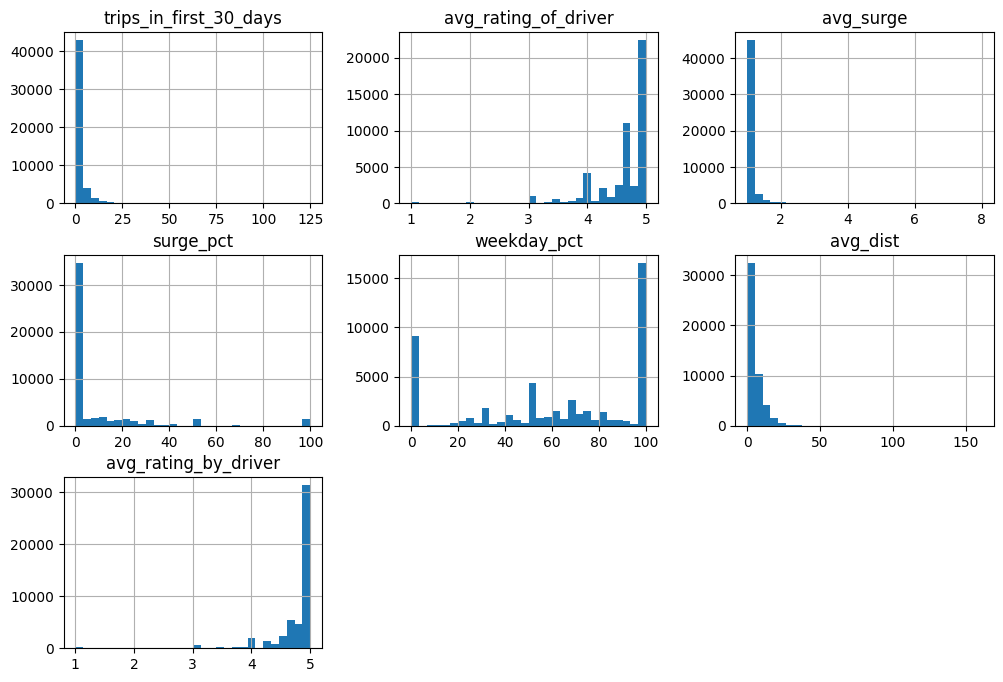

In [ ]:
num_cols = ['trips_in_first_30_days','avg_rating_of_driver','avg_surge',
            'surge_pct','weekday_pct','avg_dist','avg_rating_by_driver']
df3[num_cols].hist(bins=30, figsize=(12,8));

Histogram for categorical columns

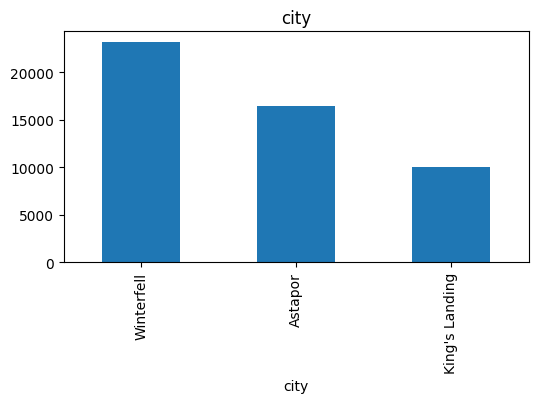

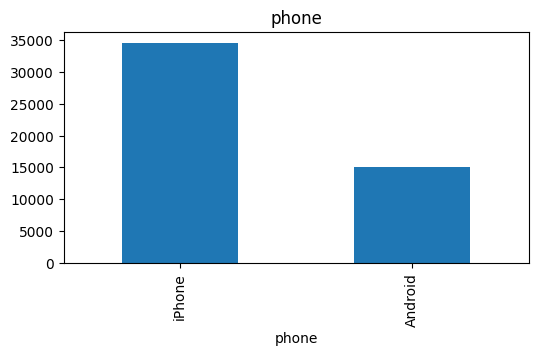

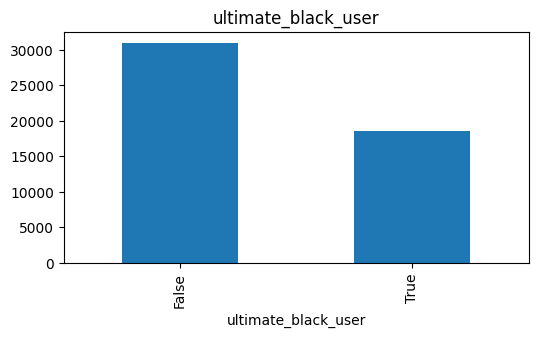

In [ ]:
for col in ['city','phone','ultimate_black_user']:
    df3[col].value_counts().plot(kind='bar', title=col, figsize=(6,3));
    plt.show()

Boxplot of the retained users for numerical columns

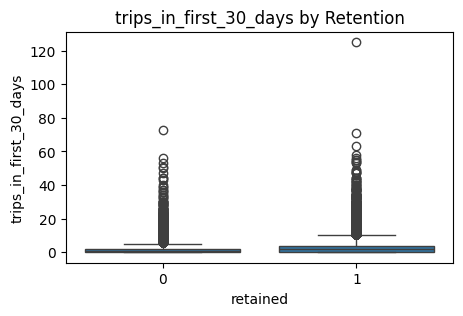

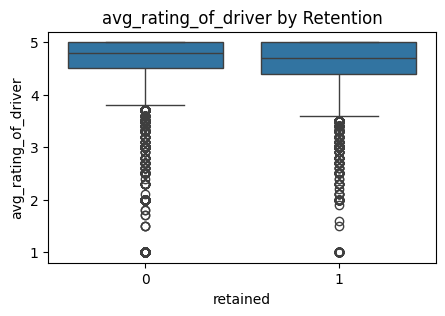

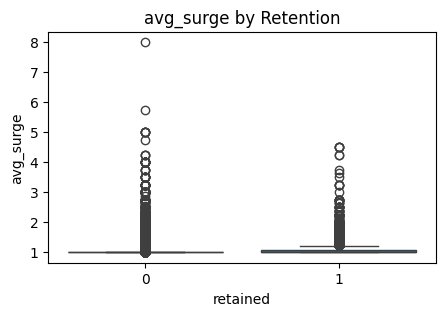

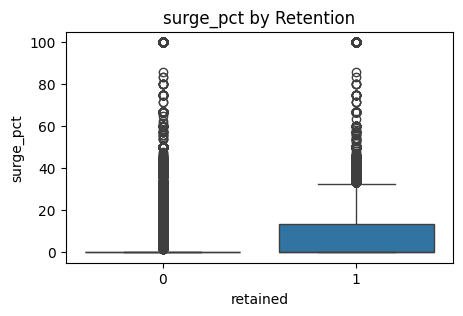

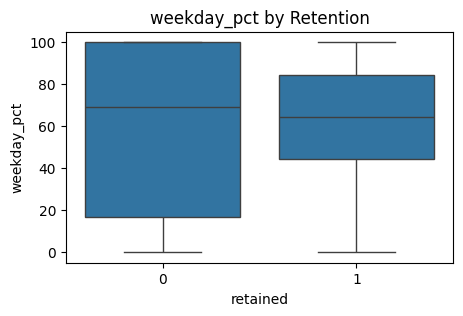

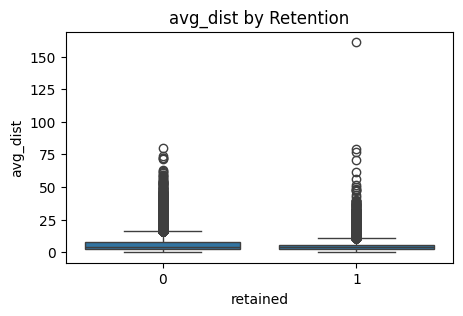

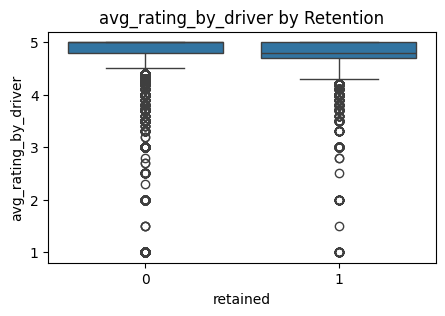

In [ ]:
for col in num_cols:
    plt.figure(figsize=(5,3))
    sns.boxplot(x='retained', y=col, data=df3)
    plt.title(f"{col} by Retention")
    plt.show()

Boxplot of the retained users for categorical columns

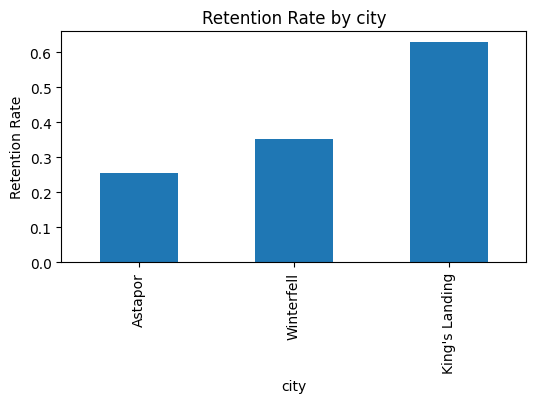

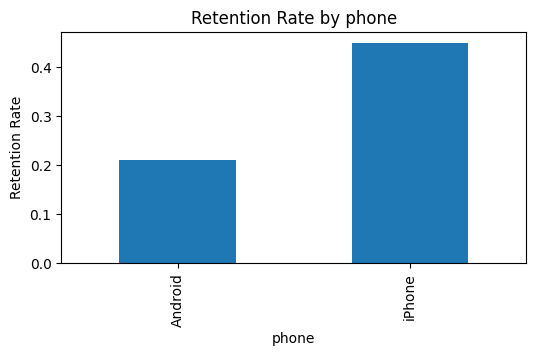

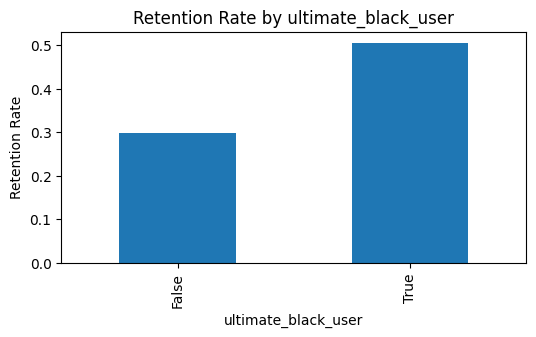

In [ ]:
for col in ['city','phone','ultimate_black_user']:
    prop = df3.groupby(col)['retained'].mean().sort_values()
    prop.plot(kind='bar', title=f"Retention Rate by {col}", figsize=(6,3))
    plt.ylabel('Retention Rate')
    plt.show()

Heatmap and pairplot for the retained users

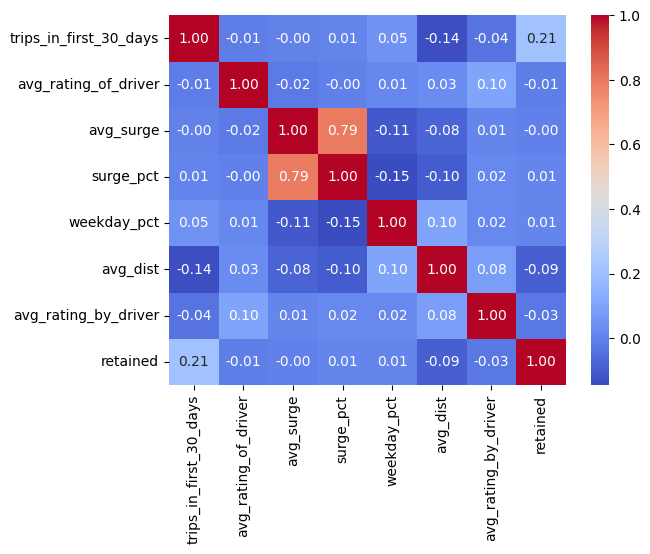

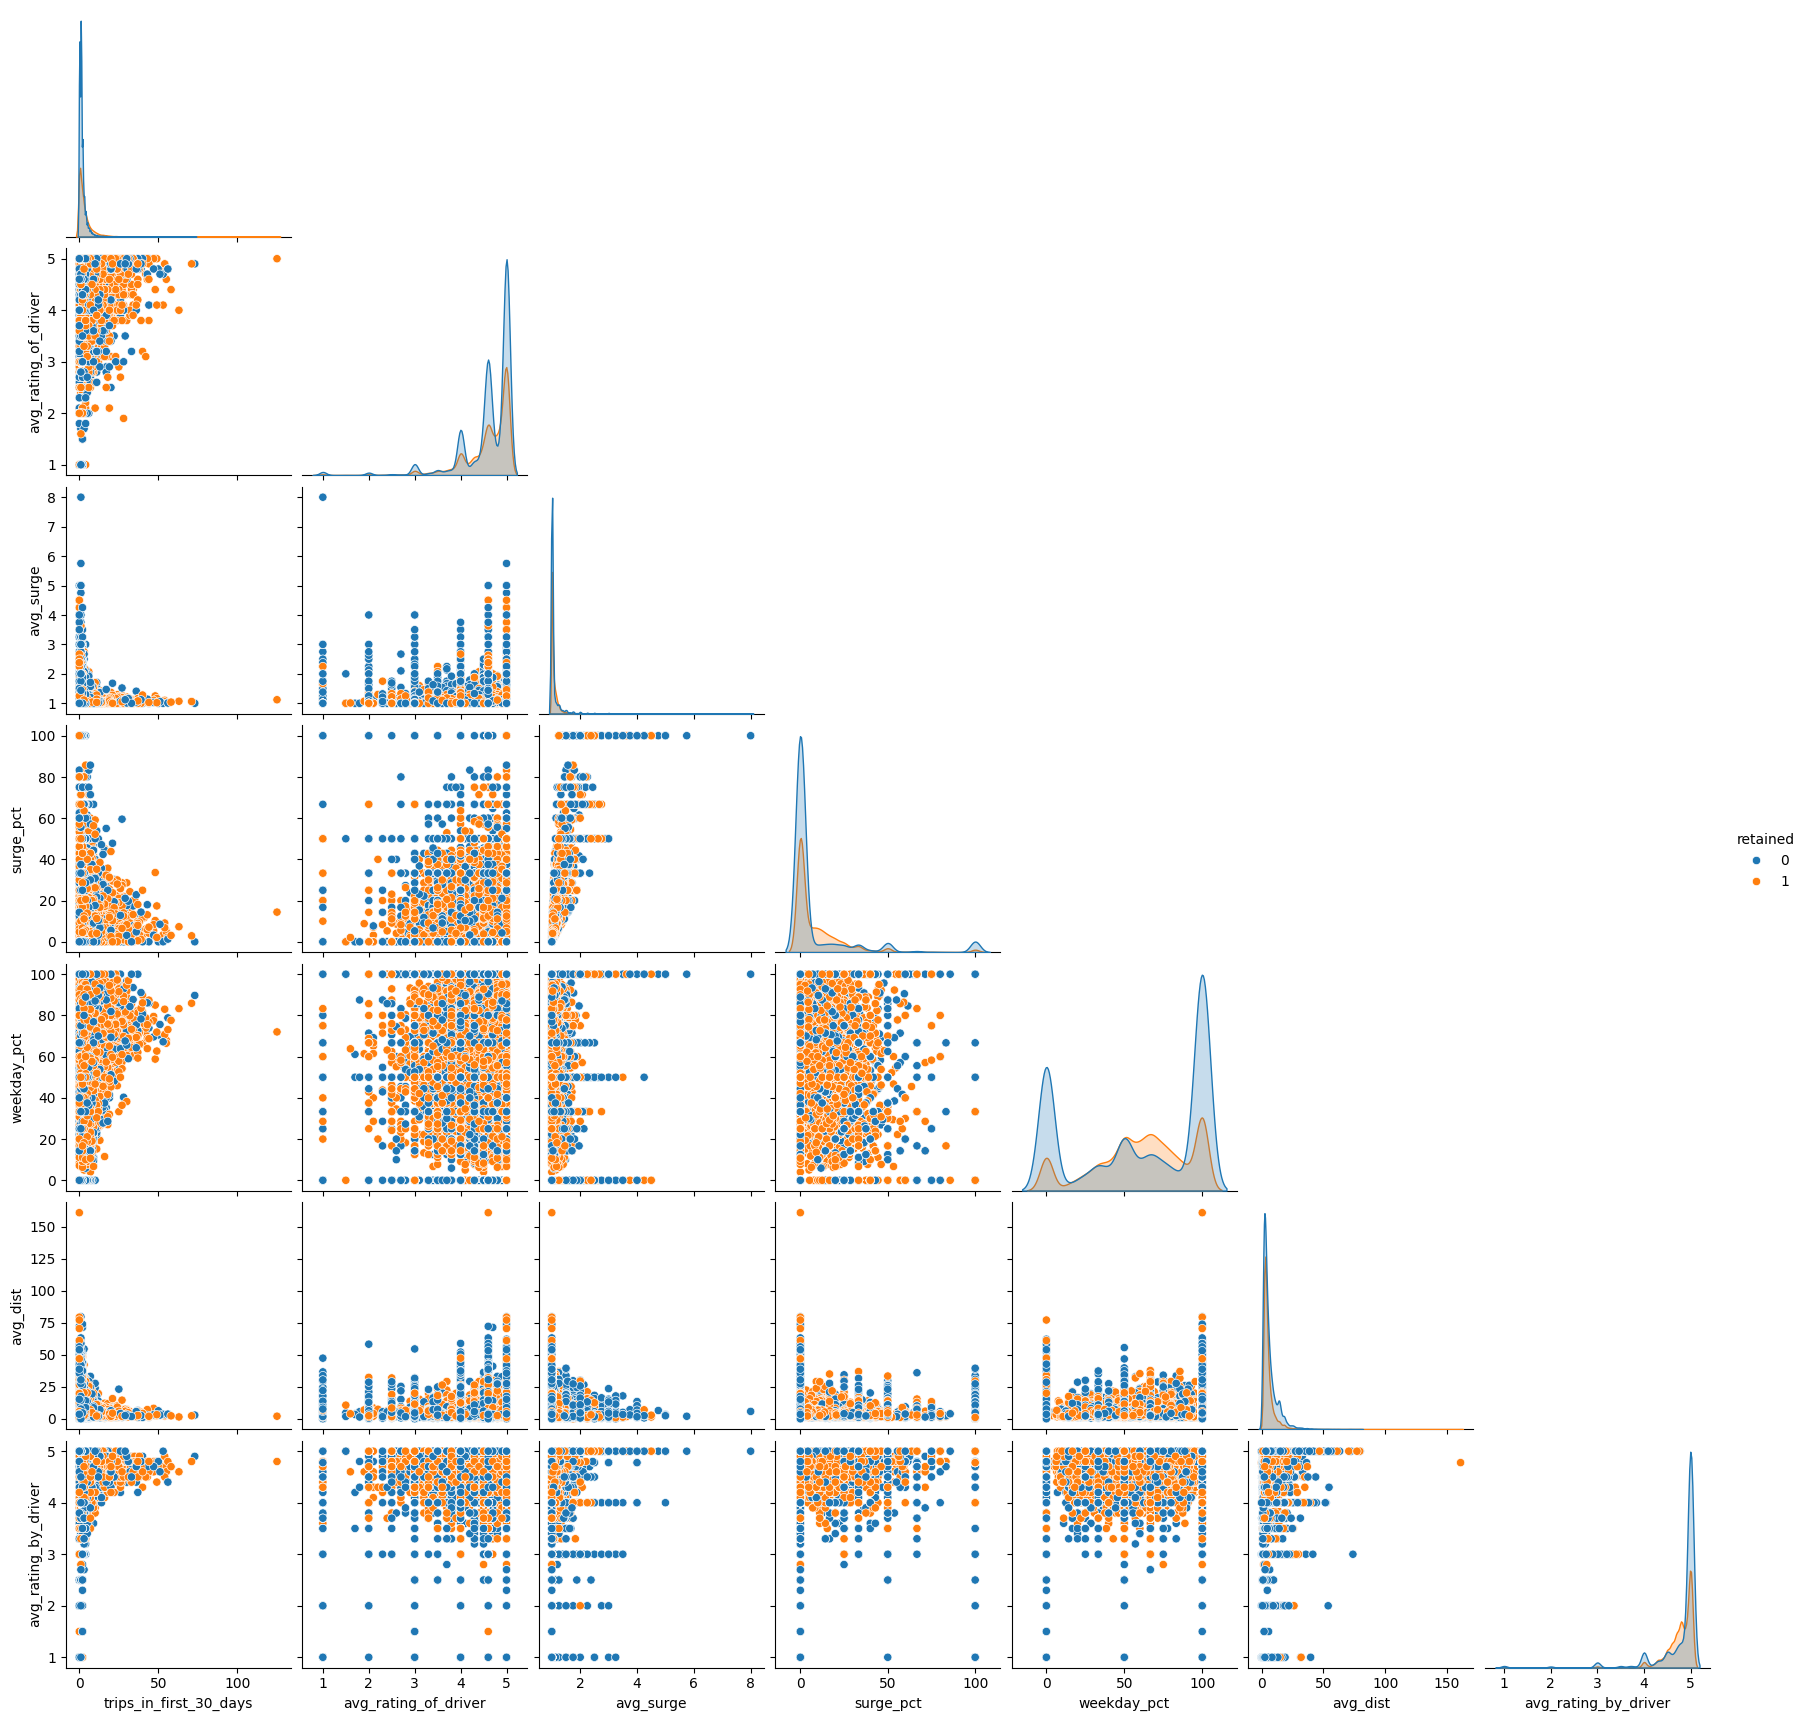

In [143]:
sns.heatmap(df3[num_cols + ['retained']].corr(), annot=True, fmt=".2f", cmap='coolwarm');
sns.pairplot(df3, vars=num_cols, hue='retained', corner=True);

# Modeling

We'll use Logistic Regression and Random Forest models in addition to hyperparamater tuning to determine the best performing model 

### Logistic Regression Classifier

In [163]:
df3.head()

,city,trips_in_first_30_days,signup_date,avg_rating_of_driver,avg_surge,last_trip_date,phone,surge_pct,ultimate_black_user,weekday_pct,avg_dist,avg_rating_by_driver,retained
0,King's Landing,4,2014-01-25,4.7,1.10,2014-06-17,iPhone,15.4,True,46.2,3.67,5.0,1
1,Astapor,0,2014-01-29,5.0,1.00,2014-05-05,Android,0.0,False,50.0,8.26,5.0,0
2,Astapor,3,2014-01-06,4.3,1.00,2014-01-07,iPhone,0.0,False,100.0,0.77,5.0,0
3,King's Landing,9,2014-01-10,4.6,1.14,2014-06-29,iPhone,20.0,True,80.0,2.36,4.9,1
4,Winterfell,14,2014-01-27,4.4,1.19,2014-03-15,Android,11.8,False,82.4,3.13,4.9,0


Removing unneeded columns

In [164]:
df_model = df3.drop(columns=['signup_date', 'last_trip_date'])

Defining X and y

In [165]:
y = df_model['retained']
X = df_model.drop(columns=['retained'])

One hot encoding

In [166]:
X = pd.get_dummies(X, drop_first=True)

Scalling all numerical columns

In [167]:
num_cols = X.select_dtypes(include=['int64','float64']).columns
scaler = StandardScaler()
X[num_cols] = scaler.fit_transform(X[num_cols])

Train/test split

In [168]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

In [169]:
lr = LogisticRegression(max_iter=200, class_weight='balanced')
lr.fit(X_train, y_train)

y_pred  = lr.predict(X_test)
y_proba = lr.predict_proba(X_test)[:,1]

print(classification_report(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_proba))

              precision    recall  f1-score   support

           0       0.78      0.72      0.75      7733
           1       0.59      0.66      0.62      4668

    accuracy                           0.70     12401
   macro avg       0.68      0.69      0.68     12401
weighted avg       0.70      0.70      0.70     12401

ROC AUC: 0.7540752521134066


### Logistic Regression Hyperparameter Tunining

In [ ]:
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(
    estimator=LogisticRegression(
        penalty='l2',
        solver='liblinear', 
        class_weight='balanced',
        max_iter=200
    ),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)
print("Best C:", grid.best_params_['C'])
print("Best CV ROC AUC:", grid.best_score_.round(3))

Best C: 0.1
Best CV ROC AUC: 0.763


In [172]:
best_lr = grid.best_estimator_
y_pred  = best_lr.predict(X_test)
y_proba = best_lr.predict_proba(X_test)[:,1]

print("\nTest set performance:")
print(classification_report(y_test, y_pred))
print("Test ROC AUC:", roc_auc_score(y_test, y_proba).round(3))


Test set performance:
              precision    recall  f1-score   support

           0       0.78      0.72      0.75      7733
           1       0.59      0.66      0.62      4668

    accuracy                           0.70     12401
   macro avg       0.68      0.69      0.68     12401
weighted avg       0.70      0.70      0.70     12401

Test ROC AUC: 0.754


We see that the hyperparam tuned Logistic Regression classifier performed equally as the untuned classifier, lets now try Random Forest

### Random Forest Classifier

In [ ]:
df_model = df3.drop(columns=['signup_date','last_trip_date'])
X = df_model.drop(columns=['retained'])
y = df_model['retained']

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred  = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:,1]
print("Random Forest Test Classification Report:\n")
print(classification_report(y_test, y_pred))
print("Random Forest Test ROC AUC:", roc_auc_score(y_test, y_proba).round(3))

Random Forest Test Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.82      0.80      7733
           1       0.68      0.64      0.66      4668

    accuracy                           0.75     12401
   macro avg       0.73      0.73      0.73     12401
weighted avg       0.75      0.75      0.75     12401

Random Forest Test ROC AUC: 0.817


### Random Forest Hyperparameter Tunining

In [ ]:
rf = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators':     [100, 200, 500],
    'max_depth':        [None, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train, y_train)

print("Best RF params:", grid_rf.best_params_)
print("Best CV ROC-AUC:", grid_rf.best_score_.round(3))

best_rf = grid_rf.best_estimator_
y_pred_rf   = best_rf.predict(X_test)
y_proba_rf  = best_rf.predict_proba(X_test)[:,1]

print("\nRandom Forest Test Classification Report:\n")
print(classification_report(y_test, y_pred_rf))
print("Test ROC-AUC:", roc_auc_score(y_test, y_proba_rf).round(3))

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best RF params: {'max_depth': None, 'min_samples_leaf': 10, 'n_estimators': 500}
Best CV ROC-AUC: 0.854

Random Forest Test Classification Report:

              precision    recall  f1-score   support

           0       0.83      0.80      0.81      7733
           1       0.68      0.73      0.70      4668

    accuracy                           0.77     12401
   macro avg       0.75      0.76      0.76     12401
weighted avg       0.77      0.77      0.77     12401

Test ROC-AUC: 0.844


The hypertuned random forest model is our top performer, lets analyze it further

In [183]:
y_pred_rf  = best_rf.predict(X_test)
y_proba_rf = best_rf.predict_proba(X_test)[:,1]

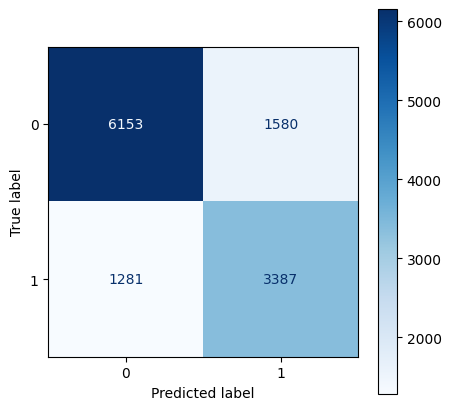

In [208]:
cm = confusion_matrix(y_test, y_pred_rf, labels=best_rf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_rf.classes_)
fig, ax = plt.subplots(figsize=(5,5))
disp.plot(cmap='Blues', ax=ax);

The model correctly predicts 6,153 non-retained and 3,387 retained users, but still misclassifies 1,580 false positives and 1,281 false negatives

avg_rating_by_driver      0.182087
weekday_pct               0.133460
city_King's Landing       0.132000
surge_pct                 0.112012
avg_dist                  0.103207
avg_surge                 0.081292
phone_iPhone              0.073421
trips_in_first_30_days    0.070602
ultimate_black_user       0.053871
avg_rating_of_driver      0.040469
dtype: float64


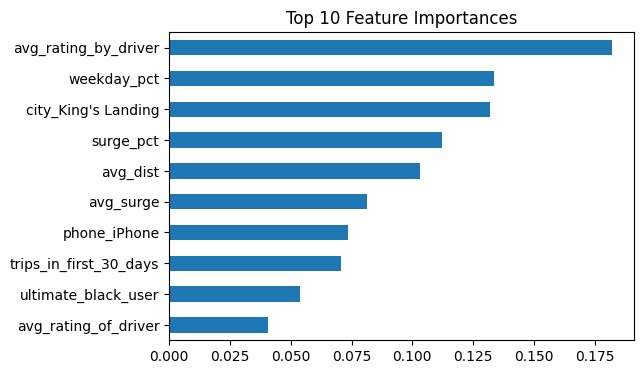

In [207]:
feat_imp = pd.Series(best_rf.feature_importances_, index=X.columns)
top10 = feat_imp.sort_values(ascending=False).head(10)

plt.figure(figsize=(6,4))
top10.plot(kind='barh')
plt.gca().invert_yaxis() 
plt.title('Top 10 Feature Importances')
print(top10)

The rider’s average rating by drivers is the single strongest predictor of user retention, followed by the proportion of weekday trips and being based in King’s Landing

### Suggestions to Ultimate

- Reward high quality riders by giving them loyalty points or early access to promotions, reinforcing the behavior that correlates most strongly with ongoing activity
- Drive more weekday usage via targeted mid-week discounts
- Onboard aggressively in month one, encouraging a minimum number of trips (or a “first ride” credit) within 30 days to hit that early activity threshold that boosts long term loyalty

Together, these actions translate our top predictors into concepts that improve service quality, consistency of use, and early engagement to lift retention across the platform.